# Data Preprocessing for Peptide-HLA Binding Prediction

This notebook prepares the raw MHC ligand dataset for downstream model training. The process
involves:

1. Data extraction, reformatting
1. Filtering invalid sequences
1. Analysis of uniqueness and measurement alignment (Quantitative vs Qualitative)
1. Resolving conflicts (Deduplication)
1. Exploratory Data Analysis (EDA)
1. Balancing the dataset with synthetic negatives
1. Exporting to CSV format

We begin by installing specific versions of our required libraries to guarantee reproducibility.

In [29]:
%%capture
# Install strict versions for reproducibility
%pip install --index-url https://pypi.org/simple pandas==3.0.1 numpy==2.4.2 scipy==1.17.1 matplotlib==3.10.8 seaborn==0.13.2 ipython==9.10.0

In [30]:
import os
import types
import random
from collections.abc import Set, Mapping
from collections import Counter

import numpy as np
import pandas as pd
from scipy.stats import gmean
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display


class Globals:
    """
    Container for explicit global state.
    """

    # Reproducibility seed
    SEED: int = 42

    # Amino acid frequencies from Swiss-Prot
    SWISSPROT_AA_PROBS: Mapping[str, float] = types.MappingProxyType(
        {
            "A": 0.0825,
            "R": 0.0553,
            "N": 0.0406,
            "D": 0.0545,
            "C": 0.0137,
            "Q": 0.0393,
            "E": 0.0675,
            "G": 0.0707,
            "H": 0.0227,
            "I": 0.0596,
            "L": 0.0966,
            "K": 0.0584,
            "M": 0.0242,
            "F": 0.0386,
            "P": 0.0470,
            "S": 0.0656,
            "T": 0.0534,
            "W": 0.0108,
            "Y": 0.0292,
            "V": 0.0687,
        }
    )
    ALLOWED_AMINO_ACIDS: frozenset = frozenset(SWISSPROT_AA_PROBS.keys())

    RAW_DATA_PATH: str = "data/raw/mhc_ligand_table_export.csv"
    PROCESSED_DATA_DIR: str = "data/processed"
    PROCESSED_DATA_PATH: str = os.path.join(PROCESSED_DATA_DIR, "training_data.csv")
    # We will hold our working dataframes here instead of polluting true globals
    unreformatted_raw_df: pd.DataFrame | None = None
    raw_data_df: pd.DataFrame | None = None
    deduplicated_df: pd.DataFrame | None = None
    filtered_df: pd.DataFrame | None = None
    balanced_df: pd.DataFrame | None = None


# Ensure the processed data directory exists
os.makedirs(Globals.PROCESSED_DATA_DIR, exist_ok=True)

# Set seed for reproducability
random.seed(Globals.SEED)
np.random.seed(Globals.SEED)

## 1. Data Extraction & Reformatting

We begin by loading the raw CSV file. We retain only the columns relevant for training: Sequence,
Qualitative Measurement, and Quantitative Measurement. We rename these columns for consistency but do not perform deep cleaning yet.

In [31]:
def load_raw_data(file_path: str) -> pd.DataFrame:
    """
    Loads the raw CSV data.
    """
    return pd.read_csv(file_path, low_memory=False)


def explore_raw_data(input_df: pd.DataFrame) -> None:
    """
    Prints information about the raw dataframe, including column types and a sample.
    """
    print(f"Raw dataset shape: {input_df.shape}")
    print("\nColumn types:")
    print(input_df.dtypes)
    print("\nSample of the raw data (first 3 rows):")
    display(input_df.head(3))


def reformat_data(input_df: pd.DataFrame) -> pd.DataFrame:
    """
    Selects the relevant columns and renames them appropriately.
    """
    subset_df: pd.DataFrame = input_df[
        ["Epitope - Name", "Assay - Qualitative Measurement", "Assay - Quantitative measurement"]
    ]
    reformatted_df: pd.DataFrame = subset_df.iloc[1:].copy()

    reformatted_df.rename(
        columns={
            "Epitope - Name": "Sequence",
            "Assay - Qualitative Measurement": "Qualitative measurement",
            "Assay - Quantitative measurement": "Quantitative measurement",
        },
        inplace=True,
    )

    return reformatted_df


Globals.unreformatted_raw_df = load_raw_data(Globals.RAW_DATA_PATH)
explore_raw_data(Globals.unreformatted_raw_df)

Globals.raw_data_df = reformat_data(Globals.unreformatted_raw_df)
print("Reformatted Data Sample:")
display(Globals.raw_data_df.head(3))

Raw dataset shape: (48865, 4)

Column types:
Assay ID - IEDB IRI                     str
Epitope - Name                          str
Assay - Qualitative Measurement         str
Assay - Quantitative measurement    float64
dtype: object

Sample of the raw data (first 3 rows):


,Assay ID - IEDB IRI,Epitope - Name,Assay - Qualitative Measurement,Assay - Quantitative measurement
0,http://www.iedb.org/assay/2621627,ARFDSKDEILL,Positive,NaN
1,http://www.iedb.org/assay/3205017,RRFHFSQSL,Positive,NaN
2,http://www.iedb.org/assay/3203470,GRLLQQLAM,Positive,NaN


Reformatted Data Sample:


,Sequence,Qualitative measurement,Quantitative measurement
1,RRFHFSQSL,Positive,NaN
2,GRLLQQLAM,Positive,NaN
3,HRIGQTSSV,Positive,NaN


## 2. Filtering Invalid Sequences

Protein sequences for this project should consist only of the 20 standard amino acids. We filter out
sequences containing invalid characters/artifacts.

**Analysis of Dropped Sequences:** The dataset contains sequences with annotations representing
chemical modifications (e.g., Oxidation, Deamidation). These are typically denoted by a `+` followed
by a reaction code (e.g., `+ OX`, `+ DEAM`).

We drop these because:

1. **Vocabulary Compatibility**: Standard protein language models do not support these tokens.
1. **Physical Accuracy**: The modifications alter the physics of the molecule, so training on the
   stripped sequence would be misleading.

We also detect and report sequences containing unknown amino acids (denoted by `X`). This is the
case when a mass spectrometer hits a snag. We skip such samples. Also, we confirm that no other
irregularity cases are present in the data.

The percentage of discarded data is negligable.

In [ ]:
def filter_valid_sequences(input_df: pd.DataFrame) -> pd.DataFrame:
    """
    Removes rows where the standard 20 amino acid character set is violated.
    """
    initial_rows = len(input_df)

    def is_standard_sequence(seq: str) -> bool:
        return all(char in Globals.ALLOWED_AMINO_ACIDS for char in seq)

    valid_mask = input_df["Sequence"].apply(is_standard_sequence)
    valid_df = input_df[valid_mask].copy()
    invalid_df = input_df[~valid_mask].copy()

    removed_rows = initial_rows - len(valid_df)
    percentage_removed = (removed_rows / initial_rows) * 100

    print(
        f"Remaining rows: {len(valid_df)}, initial rows: {initial_rows}. "
        f"Filtered out {removed_rows} rows ({percentage_removed:.2f}%) with invalid characters."
    )

    observed_reactions = Counter()
    invalid_bases_with_unknown_aa = []
    invalid_bases_unknown_reason = []

    print("\n--- Analysis of Dropped Sequences ---")

    for seq in invalid_df["Sequence"]:
        seq_str = str(seq)
        if "+" in seq_str:
            parts = seq_str.split("+", maxsplit=1)
            if len(parts) == 2:
                remainder = parts[1].strip()
                observed_reaction = remainder.split("(")[0].strip()
                observed_reactions[observed_reaction] += 1

        base_str = seq_str.split("+", maxsplit=1)[0].strip()
        invalid_chars = sorted(
            list(set([c for c in base_str if c not in Globals.ALLOWED_AMINO_ACIDS]))
        )
        if invalid_chars:
            if invalid_chars == ["X"]:
                invalid_bases_with_unknown_aa.append(seq_str)
            else:
                invalid_bases_unknown_reason.append((seq_str, invalid_chars))

    print(f"Identified {len(observed_reactions)} observed reactions:")
    for reaction, count in observed_reactions.items():
        print(f"  {reaction}: {count}")

    print(
        f"\nSequences with unknown amino acid (X): {len(invalid_bases_with_unknown_aa)} - Showing 3 samples:"
    )
    for s in invalid_bases_with_unknown_aa[:3]:
        print(f"  {s}")

    if not invalid_bases_unknown_reason:
        print("\nNo other invalid characters present.")
    else:
        print(f"\nOther invalid sequences found: {invalid_bases_unknown_reason}")

    return valid_df


Globals.filtered_df = filter_valid_sequences(Globals.raw_data_df)

Remaining rows: 48043, initial rows: 48864. Filtered out 821 rows (1.68%) with invalid characters.

--- Analysis of Dropped Sequences ---
Identified 11 observed reactions:
  OX: 530
  DEAM: 113
  PYRE: 70
  METH: 13
  SCM: 21
  CYSTL: 34
  UNK: 3
  MCM: 21
  CITR: 3
  PHOS: 9
  GLUT: 2

Sequences with unknown amino acid (X): 5 - Showing 3 samples:
  GRDYDVYQX + UNK(X9)
  RRYNXXPVX + UNK(X5, X6, X9)
  RRXSRDGXAX

No other invalid characters present.


## 3. Uniqueness and Measurement Alignment Analysis

Before deduplication, we analyze the dataset's structure. Since this is an aggregation of multiple
assays, duplicate sequences are common. We need to understand:

1. **Duplication Rate**: How many unique sequences vs total observations?
1. **Measurement Presence**: How often do we have both quantitative (IC50) and qualitative labels?
1. **Consistency**: When both measurements exist for a row, do they align? (e.g., Low IC50 should be
   Positive). We will resolve duplicates in the next section based on these insights.

In [33]:
def print_duplicate_statistics(input_df: pd.DataFrame) -> None:
    """
    Prints statistics about duplicated sequences.
    """
    total_rows = len(input_df)
    unique_sequences = input_df["Sequence"].nunique()
    duplicate_rows = total_rows - unique_sequences

    # Calculate unique names that HAVE duplicates
    counts = input_df["Sequence"].value_counts()
    sequences_with_duplicates = counts[counts > 1].count()

    print("--- Duplication Statistics ---")
    print(f"Total Observations: {total_rows}")
    print(f"Unique Sequences: {unique_sequences} ({unique_sequences / total_rows:.2%})")
    print(f"Duplicate Observations: {duplicate_rows} ({duplicate_rows / total_rows:.2%})")
    print(
        f"Number of sequences appearing >1 time: {sequences_with_duplicates} ({sequences_with_duplicates / unique_sequences:.2%} of unique sequences)"
    )
    print("\nTop-5 most frequent sequences:")
    print(counts.head(5).to_string())
    print("\n")


# Map for Qualitative Alignment
QUALITATIVE_MAPPING: Mapping = types.MappingProxyType(
    {
        "Negative": "Negative",
        "Positive": "Positive",
        "Positive-High": "Positive",
        "Positive-Intermediate": "Positive",
        "Positive-Low": "Positive",
    }
)


def analyze_measurement_alignment(input_df: pd.DataFrame) -> None:
    """
    Analyzes consistency between Qualitative and Quantitative measurements within dimensions.
    """
    # 1. Presence Analysis
    has_qual = input_df["Qualitative measurement"].notna()
    has_quant = input_df["Quantitative measurement"].notna()
    total = len(input_df)

    presence_df = pd.DataFrame(
        {
            "Qualitative Values": [has_qual.sum(), (~has_qual).sum()],
            "Quantitative Values": [has_quant.sum(), (~has_quant).sum()],
        },
        index=["Present", "Missing"],
    )

    both_present = (has_qual & has_quant).sum()

    print("--- Measurement Presence ---")
    display(presence_df)
    print(f"Rows with BOTH measurements: {both_present} ({both_present / total:.2%})\n")

    # 2. Alignment (Consistency check)
    both_df = input_df[has_qual & has_quant].copy()

    # Map Quant to Label (< 500 is Positive)
    both_df["Quant_Label"] = both_df["Quantitative measurement"].apply(
        lambda x: "Positive" if float(x) < 500 else "Negative"
    )
    # Map Qual to Label (Simplify)
    both_df["Qual_Simplified"] = both_df["Qualitative measurement"].map(QUALITATIVE_MAPPING)

    print(
        f"--- Alignment Analysis (Subset: {both_present} rows, treating all kinds of positive labels identical) ---"
    )
    aligned_count = (both_df["Quant_Label"] == both_df["Qual_Simplified"]).sum()
    print(f"Consistent Rows: {aligned_count} ({aligned_count / both_present:.2%})")

    crosstab = pd.crosstab(both_df["Quant_Label"], both_df["Qual_Simplified"])
    crosstab.index.name = "From Quantitative (IC50)"
    crosstab.columns.name = "From Qualitative Tag"
    print("\nConfusion Matrix (Quant vs Qual):")
    display(crosstab)


print_duplicate_statistics(Globals.filtered_df)
analyze_measurement_alignment(Globals.filtered_df)

--- Duplication Statistics ---
Total Observations: 48043
Unique Sequences: 22141 (46.09%)
Duplicate Observations: 25902 (53.91%)
Number of sequences appearing >1 time: 8905 (40.22% of unique sequences)

Top-5 most frequent sequences:
Sequence
GRILSGVVTK    43
GRIGVITNR     38
HRAQVIYTR     37
GRLDAVLQR     35
GRAPISNPGM    34


--- Measurement Presence ---


,Qualitative Values,Quantitative Values
Present,48043,2210
Missing,0,45833


Rows with BOTH measurements: 2210 (4.60%)

--- Alignment Analysis (Subset: 2210 rows, treating all kinds of positive labels identical) ---
Consistent Rows: 1821 (82.40%)

Confusion Matrix (Quant vs Qual):


From Qualitative Tag,Negative,Positive
From Quantitative (IC50),,
Negative,1378,389
Positive,0,443


**Insight:** We observe that even single sequences may have conflicting labels. However,
quantitative and qualitative data generally align well. Our deduplication strategy will prioritize
**Quantitative** values as the ground truth because they represent a physical constant.

## 4. Resolving Conflicts (Deduplication)

We consolidate multiple observations of the same sequence into a single consensus entry.
**Strategy:**

1. **Quantitative Priority:** If quantitative data exists, we calculate the Geometric Mean.
   `GMean < 500` = Positive.
   - *Why Geometric Mean?* Binding affinity is exponential in nature, so geometric mean is more
     appropriate than arithmetic mean.
1. **Qualitative Fallback:** If only qualitative tags exist, we trust it if all samples have the
   same label (treating all kinds of positives as same).
1. **Discard Conflicts:** If qualitative tags disagree, we discard the ambiguous sequence.

In [34]:
def calculate_quantitative_consensus(group_quantitative_values: pd.Series) -> int:
    """
    Decides the binding status based on the geometric mean of quantitative measurements.
    Returns:
        int: 1 for Positive binding (<500nM), 0 for Negative.
    """
    values: pd.Series = group_quantitative_values.dropna().astype(float)
    geo_mean: float = gmean(values)
    return int(geo_mean < 500)


def process_quantitative_split(quant_df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Handle deduplication for sequences with quantitative data.
    Returns:
        consensus_df: DataFrame with unique 'Sequence' and 'isPositive'.
        alignment_stats: DataFrame tracking if consensus matches ANY original label.
    """
    consensus_rows = []
    stats_rows = []

    grouped = quant_df.groupby("Sequence")

    for seq, group in grouped:
        # 1. Calculate Consensus
        is_pos_int = calculate_quantitative_consensus(group["Quantitative measurement"])
        consensus_rows.append({"Sequence": seq, "isPositive": float(is_pos_int)})

        # 2. Check Alignment (Does the consensus match at least one original qualitative label?)
        group_qual_labels = group["Qualitative_Mapped"].unique()
        cons_label = "Positive" if is_pos_int == 1 else "Negative"
        # Match is True if cons_label matches any valid original label
        has_match = cons_label in group_qual_labels

        stats_rows.append({"Consensus": cons_label, "Has_Match_In_Original": has_match})

    return pd.DataFrame(consensus_rows), pd.DataFrame(stats_rows)


def process_qualitative_split(qual_only_df: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    """
    Deduplicate sequences with ONLY qualitative data.
    Returns:
        consensus_df: Deduplicated data.
        stats: Dictionary of counts (pos/neg/conflict).
    """
    results = []
    stats = {"Consistent_Pos": 0, "Consistent_Neg": 0, "Conflict": 0}

    grouped = qual_only_df.groupby("Sequence")

    for seq, group in grouped:
        # Unique non-nan labels
        labels = group["Qualitative_Mapped"].dropna().unique()

        if len(labels) == 1:
            label = labels[0]
            val = 1.0 if label == "Positive" else 0.0
            results.append({"Sequence": seq, "isPositive": val})
            if val == 1.0:
                stats["Consistent_Pos"] += 1
            else:
                stats["Consistent_Neg"] += 1
        elif len(labels) > 1:
            stats["Conflict"] += 1

    return pd.DataFrame(results), stats


def deduplicate_dataset(input_df: pd.DataFrame) -> pd.DataFrame:
    """
    Main deduplication function.
    """
    df = input_df.copy()
    # Pre-map qualitative to simple Positive/Negative
    df["Qualitative_Mapped"] = df["Qualitative measurement"].map(QUALITATIVE_MAPPING)

    quant_subset = df[df["Quantitative measurement"].notna()].copy()
    qual_subset = df[df["Quantitative measurement"].isna()].copy()

    print("--- Processing Deduplication ---")
    # 1. Quantitative
    quant_cons_df, alignment_stats = process_quantitative_split(quant_subset)
    print(f"Sequences resolved via Quantitative Consensus: {len(quant_cons_df)}")
    match_rate = alignment_stats["Has_Match_In_Original"].mean()
    print(f"  -> Alignment Rate (Consensus matches at least one original label): {match_rate:.2%}")

    # 2. Qualitative
    # Exclude sequences already resolved by quant
    resolved_seqs = set(quant_cons_df["Sequence"])
    qual_subset = qual_subset[~qual_subset["Sequence"].isin(resolved_seqs)]

    qual_cons_df, q_stats = process_qualitative_split(qual_subset)
    print(f"Sequences resolved via Qualitative Consensus: {len(qual_cons_df)}")
    print(f"  -> Consistent Positive: {q_stats['Consistent_Pos']}")
    print(f"  -> Consistent Negative: {q_stats['Consistent_Neg']}")
    print(f"  -> Conflicts Discarded: {q_stats['Conflict']}")

    final_df = pd.concat([quant_cons_df, qual_cons_df], ignore_index=True)

    # Retention Stats
    original_count = len(input_df)
    final_count = len(final_df)
    print(
        f"\nFinal Deduplicated Count: {final_count} (Retained {final_count / original_count:.2%} of original observations)"
    )

    return final_df


Globals.deduplicated_df = deduplicate_dataset(Globals.filtered_df)

--- Processing Deduplication ---
Sequences resolved via Quantitative Consensus: 2004
  -> Alignment Rate (Consensus matches at least one original label): 85.18%
Sequences resolved via Qualitative Consensus: 20132
  -> Consistent Positive: 19727
  -> Consistent Negative: 405
  -> Conflicts Discarded: 5

Final Deduplicated Count: 22136 (Retained 46.08% of original observations)


## 5. Exploratory Data Analysis (EDA)

Now that we have a clean, unique dataset, we analyze the class balance and length distributions to
determine if balancing is strictly necessary.

--- Class Balance: Before Balancing ---
Positive: 20069 (90.66%)
Negative: 2067 (9.34%)



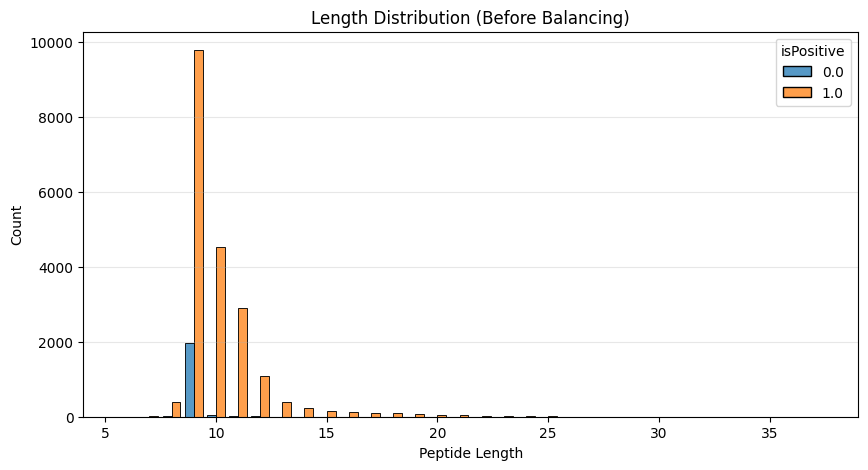

In [35]:
def analyze_class_balance(df: pd.DataFrame, title: str) -> None:
    """
    Prints and plots class balance.
    """
    counts = df["isPositive"].value_counts()
    total = len(df)
    print(f"--- Class Balance: {title} ---")
    print(f"Positive: {counts.get(1.0, 0)} ({counts.get(1.0) / total:.2%})")
    print(f"Negative: {counts.get(0.0, 0)} ({counts.get(0.0) / total:.2%})\n")


def plot_length_distribution(input_df: pd.DataFrame, title: str) -> None:
    """
    Plots length distribution by class.
    """
    df = input_df.copy()
    df["Length"] = df["Sequence"].apply(len)

    plt.figure(figsize=(10, 5))
    sns.histplot(data=df, x="Length", hue="isPositive", multiple="dodge", discrete=True, shrink=0.8)
    plt.title(title)
    plt.xlabel("Peptide Length")
    plt.grid(axis="y", alpha=0.3)
    plt.show()


analyze_class_balance(Globals.deduplicated_df, "Before Balancing")
plot_length_distribution(Globals.deduplicated_df, "Length Distribution (Before Balancing)")

## 6. Balancing with Synthetic Negatives

To address class imbalance, we generate synthetic negatives by sampling amino acids based on
Swiss-Prot frequencies and lengths based on our positive examples.

In [36]:
def generate_synthetic_sequence(length: int, existing_set: Set[str]) -> str:
    """
    Generates a random sequence of given length.
    """
    while True:
        amino_acids = list(Globals.SWISSPROT_AA_PROBS.keys())
        amino_acids_prob = list(Globals.SWISSPROT_AA_PROBS.values())
        new_seq = "".join(random.choices(amino_acids, weights=amino_acids_prob, k=length))
        if new_seq not in existing_set:
            return new_seq


def balance_dataset(input_df: pd.DataFrame) -> pd.DataFrame:
    """
    Adds synthetic negatives to achieve 1:1 balance.
    """
    pos_df = input_df[input_df["isPositive"] == 1.0]
    neg_df = input_df[input_df["isPositive"] == 0.0]

    n_pos = len(pos_df)
    n_neg = len(neg_df)
    needed = n_pos - n_neg

    print(f"Generating {needed} synthetic negatives...")
    # Sample lengths from positives to match distribution
    pos_lengths = pos_df["Sequence"].apply(len)
    existing_seqs = set(input_df["Sequence"])

    synthetic = []
    for _ in range(needed):
        l = np.random.choice(pos_lengths)
        s = generate_synthetic_sequence(l, existing_seqs)
        synthetic.append(s)
        existing_seqs.add(s)

    syn_df = pd.DataFrame({"Sequence": synthetic, "isPositive": 0.0})
    balanced = pd.concat([input_df, syn_df], ignore_index=True)

    return balanced


Globals.balanced_df = balance_dataset(Globals.deduplicated_df)

Generating 18002 synthetic negatives...


### 6.1 Post-Balancing Verification

--- Class Balance: After Balancing ---
Positive: 20069 (50.00%)
Negative: 20069 (50.00%)



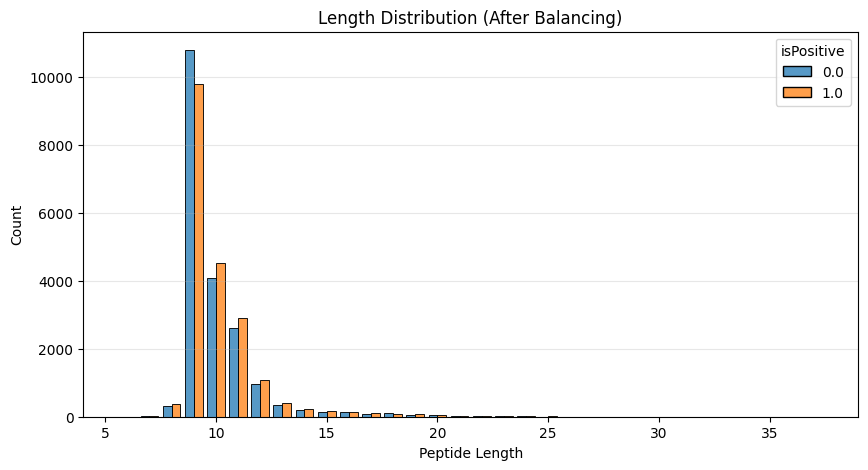

In [37]:
analyze_class_balance(Globals.balanced_df, "After Balancing")
plot_length_distribution(Globals.balanced_df, "Length Distribution (After Balancing)")

## 7. Exporting Processed Data

We save the final dataset as a CSV file with `sequence` and `is_binded` columns.

In [38]:
def save_processed_data(input_df: pd.DataFrame, file_path: str) -> None:
    """
    Saves dataframe to CSV.
    """
    df = input_df.copy()
    df.rename(columns={"isPositive": "is_binded", "Sequence": "sequence"}, inplace=True)
    df = df[["sequence", "is_binded"]]

    df.to_csv(file_path, index=False)
    print(f"Saved to {file_path}")
    print(f"Rows: {len(df)}")


save_processed_data(Globals.balanced_df, Globals.PROCESSED_DATA_PATH)

Saved to data/processed/training_data.csv
Rows: 40138
